# Instance segmentation — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **How many objects per image, and do they overlap or touch?** (touching objects are why instance masks exist)
2. **Do the polygons trace the objects?** (draw the masks and look)
3. **How big are the objects?** (masks of tiny objects are only a few pixels)

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/instance_segmentation/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("instance_segmentation", cfg)
print("task:", "instance_segmentation", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: instance_segmentation | data: data/demo/instance_segmentation | outputs: outputs/instance_segmentation_quick


## How the data is organised
Same COCO file as detection, but **every annotation also needs `segmentation`** — one or more polygons `[x1, y1, x2, y2, …]` tracing the object. The kit rasterizes the polygons into masks on the fly. RLE masks (`iscrowd`) are not supported.

## Objects and mask sizes

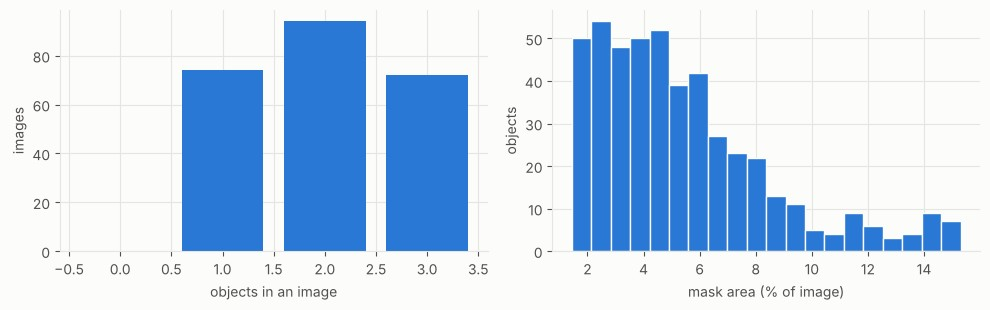

240 images, 478 instances; smallest mask covers 1.44% of its image


In [3]:
import numpy as np
from PIL import Image
from cvkit.coco import load_coco, polygons_to_mask
from cvkit.viz import draw_boxes, image_grid, overlay_masks

coco = load_coco(cfg["data"]["root"], cfg["data"].get("annotations", "annotations.json"), cfg["data"].get("images_dir", "images"))
classes, items = coco["classes"], coco["images"]

def show(im):
    anns = im["annotations"]
    masks = np.stack([polygons_to_mask(a["segmentation"], im["height"], im["width"]) for a in anns])
    shaded = overlay_masks(Image.open(im["path"]), masks, [a["label"] for a in anns])
    return draw_boxes(shaded, [a["bbox"] for a in anns], [a["label"] for a in anns], classes=classes, width=1)
import matplotlib.pyplot as plt
from cvkit.viz import BLUE

per_image = np.array([len(im["annotations"]) for im in items])
areas = np.array([polygons_to_mask(a["segmentation"], im["height"], im["width"]).mean() for im in items for a in im["annotations"]])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
vals = np.bincount(per_image); a1.bar(range(len(vals)), vals, color=BLUE); a1.set_xlabel("objects in an image"); a1.set_ylabel("images")
a2.hist(areas * 100, bins=20, color=BLUE, edgecolor="#fcfcfb"); a2.set_xlabel("mask area (% of image)"); a2.set_ylabel("objects")
plt.tight_layout(); plt.show()
print(f"{len(items)} images, {len(areas)} instances; smallest mask covers {areas.min():.2%} of its image")

## Do the masks match the objects?

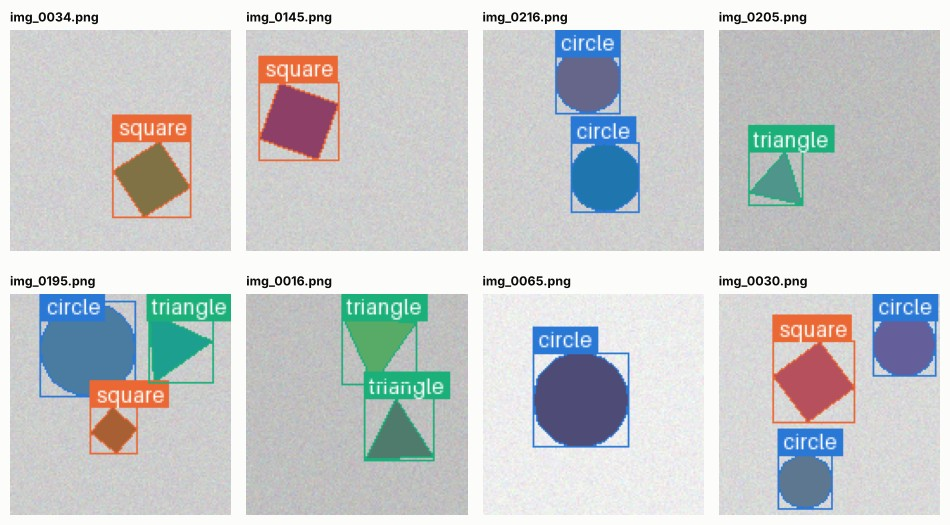

In [4]:
import random
rng = random.Random(1)
pick = rng.sample(items, min(8, len(items)))
_ = image_grid([show(im) for im in pick], [Path(im["path"]).name for im in pick], cols=4, cell=2.4)

## Augmentation
Flips must move the **masks and boxes with the pixels**, which torchvision's v2 transforms do. Same image, four random draws:

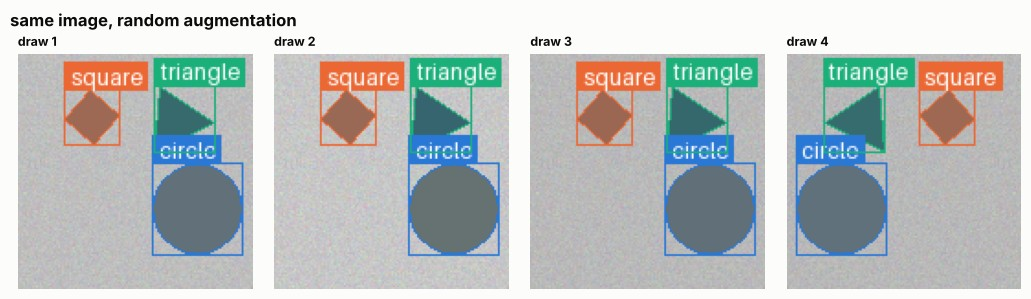

In [5]:
import torch
from torchvision.transforms.functional import to_pil_image
from cvkit.detection import build_coco_datasets
from cvkit.viz import draw_boxes, image_grid, overlay_masks

train_ds = build_coco_datasets(cfg, with_masks=True)["train"]
shown = []
for _ in range(4):
    img, tgt = train_ds[0]
    shaded = overlay_masks(to_pil_image(img), tgt["masks"].as_subclass(torch.Tensor).numpy(), tgt["labels"].numpy())
    shown.append(draw_boxes(shaded, tgt["boxes"].as_subclass(torch.Tensor).numpy(), tgt["labels"].numpy(), classes=classes, width=1))
_ = image_grid(shown, [f"draw {i}" for i in range(1, 5)], cols=4, cell=2.6, suptitle="same image, random augmentation")

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

In [6]:
from cvkit.detection import build_coco_loaders

loaders = build_coco_loaders(cfg, with_masks=True)
images, targets = next(iter(loaders["train"]))
t = targets[0]
print(f"a batch is a tuple of {len(images)} images; each target has: {list(t)}")
print("boxes", tuple(t["boxes"].shape), "| masks", tuple(t["masks"].shape), "(one H x W mask per object) | labels", t["labels"].tolist())

a batch is a tuple of 8 images; each target has: ['boxes', 'labels', 'masks']
boxes (1, 4) | masks (1, 128, 128) (one H x W mask per object) | labels [3]


## Before moving on
- [ ] Polygons trace the objects
- [ ] You know whether objects overlap (that's the case instance masks are for)
- [ ] Every annotation has a `segmentation`
- [ ] Small objects are large enough to survive `image_size`

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.